<a href="https://colab.research.google.com/github/Hyndavi7/bike-sales-europe-analysis/blob/main/bike_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Phase 1: Data Cleaning & Preprocessing

# Data Cleaning & Exploratory Analysis: Bike Sales in Europe
By **Hyndavi Dusa** | Tech Stack: Python, Pandas, Matplotlib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
df=pd.read_csv('/content/drive/MyDrive/sales_data.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113036 entries, 0 to 113035
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   Date              113036 non-null  object
 1   Day               113036 non-null  int64 
 2   Month             113036 non-null  object
 3   Year              113036 non-null  int64 
 4   Customer_Age      113036 non-null  int64 
 5   Age_Group         113036 non-null  object
 6   Customer_Gender   113036 non-null  object
 7   Country           113036 non-null  object
 8   State             113036 non-null  object
 9   Product_Category  113036 non-null  object
 10  Sub_Category      113036 non-null  object
 11  Product           113036 non-null  object
 12  Order_Quantity    113036 non-null  int64 
 13  Unit_Cost         113036 non-null  int64 
 14  Unit_Price        113036 non-null  int64 
 15  Profit            113036 non-null  int64 
 16  Cost              113036 non-null  int

In [ ]:
df.shape

(113036, 18)

In [ ]:
df.head()

,Date,Day,Month,Year,Customer_Age,Age_Group,Customer_Gender,Country,State,Product_Category,Sub_Category,Product,Order_Quantity,Unit_Cost,Unit_Price,Profit,Cost,Revenue
0,2013-11-26,26,November,2013,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
1,2015-11-26,26,November,2015,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
2,2014-03-23,23,March,2014,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,23,45,120,1366,1035,2401
3,2016-03-23,23,March,2016,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,20,45,120,1188,900,2088
4,2014-05-15,15,May,2014,47,Adults (35-64),F,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,4,45,120,238,180,418


In [ ]:
df.isnull().sum()

,0
Date,0
Day,0
Month,0
Year,0
Customer_Age,0
Age_Group,0
Customer_Gender,0
Country,0
State,0
Product_Category,0


In [ ]:
df.duplicated().sum()

np.int64(1000)

In [ ]:
df.drop_duplicates()

,Date,Day,Month,Year,Customer_Age,Age_Group,Customer_Gender,Country,State,Product_Category,Sub_Category,Product,Order_Quantity,Unit_Cost,Unit_Price,Profit,Cost,Revenue
0,2013-11-26,26,November,2013,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
1,2015-11-26,26,November,2015,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
2,2014-03-23,23,March,2014,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,23,45,120,1366,1035,2401
3,2016-03-23,23,March,2016,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,20,45,120,1188,900,2088
4,2014-05-15,15,May,2014,47,Adults (35-64),F,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,4,45,120,238,180,418
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113031,2016-04-12,12,April,2016,41,Adults (35-64),M,United Kingdom,England,Clothing,Vests,"Classic Vest, S",3,24,64,112,72,184
113032,2014-04-02,2,April,2014,18,Youth (<25),M,Australia,Queensland,Clothing,Vests,"Classic Vest, M",22,24,64,655,528,1183
113033,2016-04-02,2,April,2016,18,Youth (<25),M,Australia,Queensland,Clothing,Vests,"Classic Vest, M",22,24,64,655,528,1183
113034,2014-03-04,4,March,2014,37,Adults (35-64),F,France,Seine (Paris),Clothing,Vests,"Classic Vest, L",24,24,64,684,576,1260


In [ ]:
df['Date'].dtype

dtype('O')

In [ ]:
df['Date']=pd.to_datetime(df['Date'])
print(df['Date'].dtype)

datetime64[ns]


In [ ]:
expected_cost=df['Order_Quantity']*df['Unit_Cost']
expected_revenue=df['Order_Quantity']*df['Unit_Price']
expected_profit=df['Revenue']-df['Cost']

cost_errors=(df['Cost'].round(2)!=expected_cost.round(2)).sum()
revenue_errors=(df['Revenue'].round(2)!=expected_revenue.round(2)).sum()
profit_errors=(df['Profit'].round(2)!=expected_profit.round(2)).sum()

print(f"cost mismatches:{cost_errors} rows")
print(f"revenue mismatches:{revenue_errors} rows")
print(f"profit mismatches:{profit_errors} rows")

cost mismatches:0 rows
revenue mismatches:106467 rows
profit mismatches:0 rows


In [ ]:
df['Revenue']=df['Order_Quantity']*df['Unit_Price']
df['Profit']=df['Revenue']-df['Cost']

new_revenue_errors=(df['Revenue'].round(2)!=(df['Order_Quantity']*df['Unit_Price']).round(2)).sum()
new_profit_errors=(df['Profit'].round(2)!=(df['Revenue']-df['Cost']).round(2)).sum()

print(f"Remaining revenue mismatches:{new_revenue_errors} rows")
print(f"Remaining profit mismatches:{new_profit_errors} rows")

Remaining revenue mismatches:0 rows
Remaining profit mismatches:0 rows


In [ ]:
df.to_csv('/content/drive/MyDrive/cleaned_sales_data.csv',index=False)
print("Saved to Google Drive")

Saved to Google Drive


## Phase 2: Exploratory Data Analysis & Visualizations

In [ ]:
print(f"Total Revenue: ${df['Revenue'].sum():,.2f}")
print(f"Total Profit: ${df['Profit'].sum():,.2f}")
print(f"Total items Sold: {df['Order_Quantity'].sum():,}\n")

print("---Sales by Country---")
print(df.groupby('Country')['Revenue'].sum().sort_values())

print("\n---Sales by Age Group---")
print(df.groupby('Age_Group')['Revenue'].sum().sort_values())

Total Revenue: $95,176,318.00
Total Profit: $42,126,410.00
Total items Sold: 1,345,316

---Sales by Country---
Country
Canada             8014536
France             9847213
Germany            9982203
United Kingdom    11090006
Australia         25427586
United States     30814774
Name: Revenue, dtype: int64

---Sales by Age Group---
Age_Group
Seniors (64+)             339700
Youth (<25)             13201837
Young Adults (25-34)    34310905
Adults (35-64)          47323876
Name: Revenue, dtype: int64


In [ ]:
print("---Profit and Revenue by Country---")
country_perf=df.groupby('Country')[['Revenue','Profit']].sum()
country_perf['Profit_Margin_%']=(country_perf['Profit']/country_perf['Revenue'])*100
print(country_perf.sort_values(ascending=False,by='Profit'))

---Profit and Revenue by Country---
                 Revenue    Profit  Profit_Margin_%
Country                                            
United States   30814774  13912871        45.150002
Australia       25427586  10901557        42.872953
United Kingdom  11090006   4857663        43.802167
Germany          9982203   4363602        43.713817
France           9847213   4294623        43.612573
Canada           8014536   3796094        47.365113


### 1. Geographical Performance Analysis
This section analyzes and identifies the top-performing European countries based on total revenue generation.

<Axes: title={'center': 'Total Revenue by Country'}, xlabel='Revenue (USD)', ylabel='Country'>

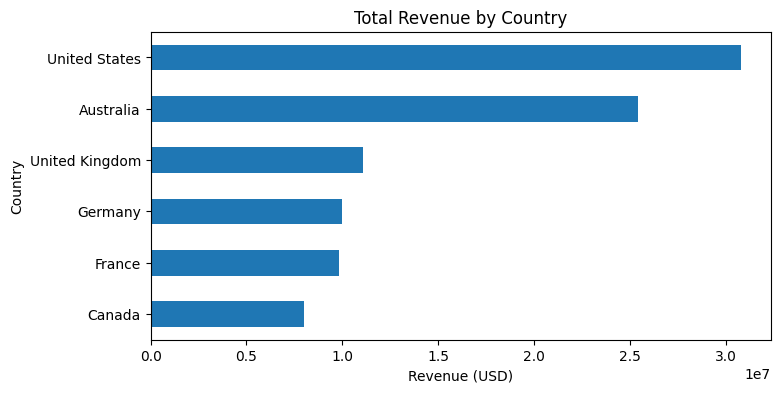

In [ ]:
df.groupby('Country')['Revenue'].sum().sort_values().plot(kind='barh',figsize=(8,4),title='Total Revenue by Country',rot=0,xlabel='Revenue (USD)',ylabel='Country',grid=False)

### 2. Customer Demographics Analysis
This section isolates purchasing power by breaking down revenue contributions across distinct customer age groups.

<Axes: title={'center': 'Revenue Contribution by Age Group'}, xlabel='Age Group', ylabel='Revenue'>

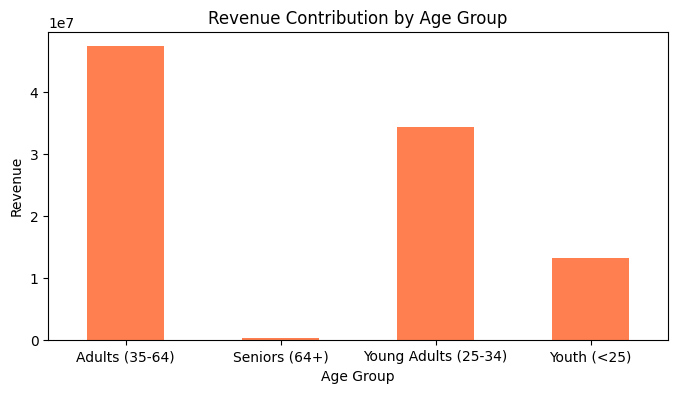

In [ ]:
df.groupby('Age_Group')['Revenue'].sum().plot(kind='bar',figsize=(8,4),title='Revenue Contribution by Age Group',color='coral',xlabel='Age Group',ylabel='Revenue',rot=0)

### 3. Financial Performace Trends
This section applies a line chart to analyze sales performance sequentially over time, tracking year-over-year business growth.

<Axes: title={'center': 'Annual Revenue Performance over Time'}, xlabel='Year', ylabel='Revenue'>

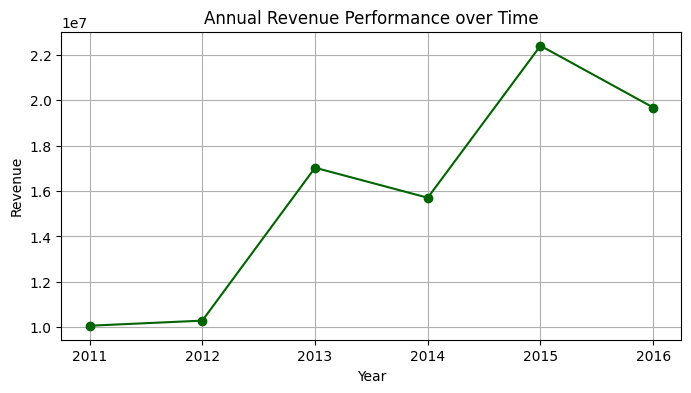

In [ ]:
df.groupby('Year')['Revenue'].sum().plot(kind='line',marker='o',title='Annual Revenue Performance over Time',figsize=(8,4),xlabel='Year',ylabel='Revenue',color='darkgreen',grid=True)